# AnaeCare — MV-HFMD paper-method adaptation (Kaggle)

**Paper:** Samuel Black and Richard Souvenir, *Multi-View Classification Using Hybrid Fusion and Mutual Distillation*, WACV 2024.  
**Paper:** https://openaccess.thecvf.com/content/WACV2024/html/Black_Multi-View_Classification_Using_Hybrid_Fusion_and_Mutual_Distillation_WACV_2024_paper.html  
**Official code:** https://github.com/vidarlab/multi-view-hybrid

## What is preserved from the paper / official repository
- Hybrid backbone: `vit_small_r26_s32_224` (pretrained ImageNet weights when available).
- Shared backbone across views and **token-level fusion**: one class token followed by the patch tokens from each view, with a learnable image/view embedding.
- Paper loss: fused-output cross entropy + mean single-view cross entropy + symmetric mutual distillation between the **average single-view logits** and fused logits.
- Official training settings: SGD, learning rate 0.01, momentum 0.9, weight decay 5e-4, One-Cycle LR, batch size 64, 50 epochs, temperature 4, distillation lambda 0.1, gradient clipping 80; select the checkpoint with highest validation accuracy. No early stopping.

## AnaeCare-specific data adaptation (not a paper method change)
The authors' public pipeline is set up for Hotels-8k, not AnaeCare. This notebook adapts the input pipeline to matched YEMAS, PALMAS and UNAS records. One deterministic representative frame is selected for each video modality because the model expects a fixed image view; therefore this run does **not** model temporal video dynamics and does not use metadata. This limitation must be stated in any report. It is an adaptation to AnaeCare, not a bit-for-bit reproduction of the Hotels-8k experiment.

### Fixed labels — do not change
- `Normal = 0`
- `Leve = 1`
- `Moderada` / `Moderado = 2`

Patient IDs are matched across all three modalities and split at patient level. Confusion-matrix rows are true labels and columns are predicted labels.


## 1. Runtime setup

In Kaggle, enable **Settings → Accelerator → GPU**. Keep Internet enabled so the pretrained ImageNet weights can be downloaded. The code deliberately stops if pretrained initialization fails rather than silently switching to random weights. The official training batch size is 64; if the Kaggle GPU runs out of memory, report the error before changing the batch size, because changing it departs from the paper's setting.


In [1]:
import os, sys, re, json, math, random, shutil, zipfile, subprocess, warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


## 2. Hybrid backbone dependency

The paper and official repository use `vit_small_r26_s32_224`. This notebook checks for that exact backbone and does not silently substitute another architecture.


In [2]:
try:
    import timm
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm==0.9.12"])
    import timm

print("timm:", timm.__version__)
MODEL_NAME = "vit_small_r26_s32_224"
available = MODEL_NAME in timm.list_models()
print(f"{MODEL_NAME} available:", available)
if not available:
    similar = [m for m in timm.list_models("*r26*s32*")][:20]
    print("Related timm model names:", similar)
    raise RuntimeError(
        f"Required hybrid backbone {MODEL_NAME!r} is not available in this timm version. "
        "Do not silently substitute a different backbone and call it the same method. "
        "Check the related model names printed above or use the official repository environment."
    )

timm: 1.0.29
vit_small_r26_s32_224 available: True


## 3. Discover the AnaeCare modality folders

The input search handles nested Kaggle folders, including duplicated directory levels such as `palmas_frames/palmas_frames/Leve/ID004`. It requires class folders `Normal`, `Leve`, and `Moderada`/`Moderado`.


In [3]:
# Kaggle paths seen in the AnaeCare workspace. Add another candidate here only if your Kaggle input mount differs.
INPUT_BASES = [
    Path("/kaggle/input/datasets/shimu080/unas-palmas-yemas"),
    Path("/kaggle/input/datasets/shimu080"),
    Path("/kaggle/input/unas-palmas-yemas"),
    Path("/kaggle/input"),
]

CLASS_ALIASES = {
    "normal": 0,
    "leve": 1,
    "moderada": 2,
    "moderado": 2,
}
LABEL_NAMES = ["Normal", "Leve", "Moderada"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
ID_PATTERN = re.compile(r"(ID\d+)", re.IGNORECASE)

def normalized_class_name(name):
    return CLASS_ALIASES.get(str(name).strip().lower())

def has_all_class_dirs(path: Path):
    if not path.is_dir():
        return False
    child_labels = {normalized_class_name(p.name) for p in path.iterdir() if p.is_dir()}
    return {0, 1, 2}.issubset(child_labels)

def discover_class_roots(base_paths, modality_keywords):
    candidates = []
    seen = set()
    for base in base_paths:
        if not base.exists():
            continue
        try:
            dirs = [base] + [p for p in base.rglob("*") if p.is_dir()]
        except Exception:
            dirs = [base]
        for p in dirs:
            try:
                if has_all_class_dirs(p):
                    resolved = str(p.resolve())
                    if resolved in seen:
                        continue
                    seen.add(resolved)
                    # Score modality-specific path components, ignoring the combined dataset folder name
                    # (e.g. "unas-palmas-yemas"), which contains all three modality words.
                    components = [part.lower() for part in p.parts
                                  if part.lower() not in {"unas-palmas-yemas", "shimu080", "input", "datasets"}]
                    score = sum(3 for kw in modality_keywords if any(kw in part for part in components))
                    # Prefer a slightly deeper candidate only as a tie-breaker.
                    score += min(len(p.parts), 20) / 100.0
                    candidates.append((score, p))
            except (PermissionError, OSError):
                pass
    candidates.sort(key=lambda x: x[0], reverse=True)
    return candidates

MODALITY_KEYWORDS = {
    "yemas": ["yemas", "fingertip", "finger"],
    "palmas": ["palmas", "palm"],
    "unas": ["unas", "nail", "fingernail"],
}

roots = {}
for modality, keywords in MODALITY_KEYWORDS.items():
    found = discover_class_roots(INPUT_BASES, keywords)
    print(f"\n{modality.upper()} candidate roots:")
    for score, path in found[:8]:
        print(f"  score={score:.2f}  {path}")
    if not found:
        raise FileNotFoundError(
            f"Could not discover class root for {modality}. "
            "A valid root must directly contain Normal, Leve, and Moderada/Moderado folders. "
            "Inspect /kaggle/input and add the exact parent path to INPUT_BASES if needed."
        )
    roots[modality] = found[0][1]

print("\nSelected roots:")
for modality, root in roots.items():
    print(f"{modality.upper()}: {root}")


YEMAS candidate roots:
  score=3.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  score=0.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  score=0.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images

PALMAS candidate roots:
  score=6.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  score=0.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  score=0.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames

UNAS candidate roots:
  score=3.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  score=0.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  score=0.08  /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames

Selected roots:
YEMAS: /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
PALMAS: /kaggle/in

## 4. Match the same patients across YEMAS, PALMAS and UNAS

For YEMAS and PALMAS, the middle image in sorted filename order is used as one deterministic representative frame. UNAS uses one representative nail image. A patient must exist in all three modalities and have the same class label in all of them; otherwise the notebook stops instead of guessing.


In [4]:
def build_modality_index(class_root: Path, modality_name: str):
    records = defaultdict(list)
    label_seen = {}
    class_dirs = [p for p in class_root.iterdir() if p.is_dir() and normalized_class_name(p.name) is not None]
    if not class_dirs:
        raise RuntimeError(f"No recognized class directories found in {class_root}")

    total_images = 0
    for class_dir in class_dirs:
        label = normalized_class_name(class_dir.name)
        for file_path in class_dir.rglob("*"):
            if not file_path.is_file() or file_path.suffix.lower() not in IMAGE_EXTS:
                continue
            match = ID_PATTERN.search(str(file_path))
            if not match:
                continue
            patient_id = match.group(1).upper()
            if patient_id in label_seen and label_seen[patient_id] != label:
                raise ValueError(
                    f"Patient {patient_id} appears under conflicting classes in {modality_name}: "
                    f"{label_seen[patient_id]} vs {label}. Stop and inspect labels."
                )
            label_seen[patient_id] = label
            records[patient_id].append(file_path)
            total_images += 1

    index = {}
    for patient_id, paths in records.items():
        paths = sorted(paths, key=lambda p: str(p).lower())
        index[patient_id] = {
            "label": label_seen[patient_id],
            "representative": paths[len(paths)//2],
            "n_images": len(paths),
        }

    print(
        f"{modality_name.upper()}: {len(index)} patient IDs, {total_images} image files; "
        f"class counts={dict(Counter(v['label'] for v in index.values()))}"
    )
    return index

modality_indexes = {
    name: build_modality_index(root, name)
    for name, root in roots.items()
}

common_ids = set.intersection(*(set(idx.keys()) for idx in modality_indexes.values()))
if not common_ids:
    raise RuntimeError(
        "No patient IDs are shared across YEMAS, PALMAS, and UNAS. "
        "This may mean patient IDs are encoded differently in the folders. "
        "Do not proceed until the ID matching is corrected."
    )

rows = []
for pid in sorted(common_ids):
    labels = {modality_indexes[m][pid]["label"] for m in modality_indexes}
    if len(labels) != 1:
        detail = {m: modality_indexes[m][pid]["label"] for m in modality_indexes}
        raise ValueError(f"Label mismatch for patient {pid}: {detail}")
    row = {"patient_id": pid, "label": labels.pop()}
    for modality in ["yemas", "palmas", "unas"]:
        row[f"{modality}_path"] = str(modality_indexes[modality][pid]["representative"])
        row[f"{modality}_n_images"] = modality_indexes[modality][pid]["n_images"]
    rows.append(row)

patients = pd.DataFrame(rows).sort_values("patient_id").reset_index(drop=True)
patients["label_name"] = patients["label"].map(dict(enumerate(LABEL_NAMES)))
print("\nMatched patients:", len(patients))
display(patients.head())
print("\nMatched class counts:")
display(patients["label_name"].value_counts().reindex(LABEL_NAMES, fill_value=0).to_frame("patients"))

if patients["patient_id"].duplicated().any():
    raise AssertionError("Patient IDs are not unique after matching.")
if set(patients["label"].unique()) != {0, 1, 2}:
    raise RuntimeError(
        f"Matched data must contain all 3 classes. Found labels={sorted(patients['label'].unique())}. "
        "Check class roots and patient matching before training."
    )

YEMAS: 834 patient IDs, 26816 image files; class counts={1: 201, 2: 75, 0: 558}
PALMAS: 829 patient IDs, 13328 image files; class counts={1: 201, 2: 74, 0: 554}
UNAS: 823 patient IDs, 826 image files; class counts={1: 200, 2: 73, 0: 550}

Matched patients: 818


,patient_id,label,yemas_path,yemas_n_images,palmas_path,palmas_n_images,unas_path,unas_n_images,label_name
0,ID001,0,/kaggle/input/datasets/shimu080/unas-palmas-ye...,32,/kaggle/input/datasets/shimu080/unas-palmas-ye...,16,/kaggle/input/datasets/shimu080/unas-palmas-ye...,1,Normal
1,ID003,0,/kaggle/input/datasets/shimu080/unas-palmas-ye...,32,/kaggle/input/datasets/shimu080/unas-palmas-ye...,16,/kaggle/input/datasets/shimu080/unas-palmas-ye...,1,Normal
2,ID004,1,/kaggle/input/datasets/shimu080/unas-palmas-ye...,32,/kaggle/input/datasets/shimu080/unas-palmas-ye...,16,/kaggle/input/datasets/shimu080/unas-palmas-ye...,1,Leve
3,ID005,2,/kaggle/input/datasets/shimu080/unas-palmas-ye...,32,/kaggle/input/datasets/shimu080/unas-palmas-ye...,16,/kaggle/input/datasets/shimu080/unas-palmas-ye...,1,Moderada
4,ID006,0,/kaggle/input/datasets/shimu080/unas-palmas-ye...,32,/kaggle/input/datasets/shimu080/unas-palmas-ye...,16,/kaggle/input/datasets/shimu080/unas-palmas-ye...,1,Normal



Matched class counts:


,patients
label_name,
Normal,547
Leve,199
Moderada,72


## 5. Patient-level stratified split

Creates 70% train / 15% validation / 15% test, with no patient appearing in more than one split. For a fair comparison with another AnaeCare model, use the same saved patient split IDs across models.


In [5]:
train_df, temp_df = train_test_split(
    patients, test_size=0.30, random_state=SEED, stratify=patients["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_ids = {
    "train": set(train_df.patient_id),
    "val": set(val_df.patient_id),
    "test": set(test_df.patient_id),
}
assert split_ids["train"].isdisjoint(split_ids["val"])
assert split_ids["train"].isdisjoint(split_ids["test"])
assert split_ids["val"].isdisjoint(split_ids["test"])
assert len(train_df) + len(val_df) + len(test_df) == len(patients)

for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{split_name}: n={len(split_df)} | {dict(Counter(split_df.label))}")
    assert set(split_df.label.unique()) == {0, 1, 2}, (
        f"{split_name} split lost a class; adjust the split strategy before training."
    )

split_dir = Path("/kaggle/working/anaecare_mvhfmd")
split_dir.mkdir(parents=True, exist_ok=True)
patients.to_csv(split_dir / "matched_patient_index.csv", index=False)
train_df.to_csv(split_dir / "train_split.csv", index=False)
val_df.to_csv(split_dir / "val_split.csv", index=False)
test_df.to_csv(split_dir / "test_split.csv", index=False)
print("Patient index and split CSVs saved to:", split_dir)

train: n=572 | {0: 383, 1: 139, 2: 50}
val: n=123 | {0: 82, 1: 30, 2: 11}
test: n=123 | {0: 82, 1: 30, 2: 11}
Patient index and split CSVs saved to: /kaggle/working/anaecare_mvhfmd


## 6. Dataset transforms and loaders

The three images are resized/cropped to 224×224 and ImageNet-normalized. Augmentation is applied independently to each view during training. Validation and test use deterministic preprocessing only.

In [6]:
IMG_SIZE = 224
BATCH_SIZE = 64  # official repository default
VAL_TEST_BATCH_SIZE = 8  # evaluation micro-batch for Kaggle GPU memory; does not change training method
NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()

# Deterministic ImageNet preprocessing for the pretrained hybrid backbone.
# No extra color jitter/rotation augmentation is added to the clinical images.
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

class AnaeCareThreeViewDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform
        required = ["patient_id", "label", "yemas_path", "palmas_path", "unas_path"]
        missing = [c for c in required if c not in self.frame.columns]
        if missing:
            raise ValueError(f"Missing columns: {missing}")
        for col in ["yemas_path", "palmas_path", "unas_path"]:
            missing_paths = [p for p in self.frame[col].tolist() if not Path(p).is_file()]
            if missing_paths:
                raise FileNotFoundError(f"{len(missing_paths)} missing files for {col}; first={missing_paths[0]}")

    def __len__(self):
        return len(self.frame)

    def _load_image(self, path):
        with Image.open(path) as im:
            return self.transform(im.convert("RGB"))

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        images = torch.stack([
            self._load_image(row["yemas_path"]),
            self._load_image(row["palmas_path"]),
            self._load_image(row["unas_path"]),
        ], dim=0)  # [3 views, RGB, H, W]
        return images, torch.tensor(int(row["label"]), dtype=torch.long), row["patient_id"]

train_ds = AnaeCareThreeViewDataset(train_df, train_transform)
val_ds = AnaeCareThreeViewDataset(val_df, eval_transform)
test_ds = AnaeCareThreeViewDataset(test_df, eval_transform)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False)
val_loader = DataLoader(val_ds, batch_size=VAL_TEST_BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False)
test_loader = DataLoader(test_ds, batch_size=VAL_TEST_BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False)

xb, yb, pidb = next(iter(train_loader))
print("Train batch image shape:", tuple(xb.shape), "(batch, 3 views, RGB, H, W)")
print("Batch labels:", yb.tolist())
print("Patient IDs:", list(pidb))


Train batch image shape: (64, 3, 3, 224, 224) (batch, 3 views, RGB, H, W)
Batch labels: [0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 2, 0, 0, 2, 0, 0, 2, 0, 1, 0, 0, 1, 0, 0, 0, 2, 2, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0]
Patient IDs: ['ID308', 'ID294', 'ID647', 'ID492', 'ID052', 'ID085', 'ID272', 'ID370', 'ID021', 'ID746', 'ID180', 'ID139', 'ID670', 'ID600', 'ID011', 'ID489', 'ID429', 'ID548', 'ID649', 'ID823', 'ID316', 'ID674', 'ID533', 'ID536', 'ID665', 'ID176', 'ID247', 'ID006', 'ID553', 'ID245', 'ID713', 'ID814', 'ID042', 'ID495', 'ID088', 'ID689', 'ID532', 'ID311', 'ID243', 'ID897', 'ID018', 'ID868', 'ID798', 'ID907', 'ID318', 'ID588', 'ID234', 'ID261', 'ID645', 'ID237', 'ID627', 'ID518', 'ID469', 'ID145', 'ID812', 'ID387', 'ID213', 'ID438', 'ID236', 'ID841', 'ID618', 'ID590', 'ID829', 'ID016']


## 6. MV-HFMD architecture and loss

The implementation below follows the paper's core architecture: shared hybrid CNN-Transformer image encoder; token-level multi-view fusion using one class token and all view patch tokens; learnable view embeddings; individual-view predictions; and fused prediction. Mutual distillation is computed between the **mean of the single-view logits** and the fused logits, with stop-gradient teacher copies in both directions, as described in the paper.


In [7]:
PRETRAINED = True
backbone = timm.create_model(MODEL_NAME, pretrained=PRETRAINED, num_classes=3)
FEATURE_DIM = int(backbone.num_features)
print("Loaded pretrained hybrid backbone:", MODEL_NAME)
print("Feature dimension:", FEATURE_DIM)

class MultiImageHybridAnaeCare(nn.Module):
    """Paper-method adaptation: shared hybrid encoder + token-level multi-view fusion."""
    def __init__(self, backbone, num_classes=3, num_views=3):
        super().__init__()
        self.backbone = backbone
        self.num_views = num_views
        dim = int(backbone.num_features)
        # The paper adds a learnable image embedding shared by all tokens from a view.
        self.image_embeddings = nn.Parameter(torch.zeros(1, num_views, 1, dim))
        nn.init.trunc_normal_(self.image_embeddings, std=0.02)
        required = ["patch_embed", "_pos_embed", "blocks", "norm", "head"]
        missing = [name for name in required if not hasattr(backbone, name)]
        if missing:
            raise RuntimeError(f"This timm backbone lacks expected ViT components {missing}; do not substitute another model silently.")

    def _encode_tokens(self, tokens):
        # Mirrors timm's ViT feature path after positional embeddings have been added.
        if hasattr(self.backbone, "patch_drop"):
            tokens = self.backbone.patch_drop(tokens)
        if hasattr(self.backbone, "norm_pre"):
            tokens = self.backbone.norm_pre(tokens)
        tokens = self.backbone.blocks(tokens)
        tokens = self.backbone.norm(tokens)
        return tokens

    def forward(self, images):
        # images: [B, V, 3, H, W]
        b, v, c, h, w = images.shape
        if v != self.num_views:
            raise ValueError(f"Expected {self.num_views} views, got {v}")
        flat = images.reshape(b * v, c, h, w)
        patch_tokens = self.backbone.patch_embed(flat)
        # Apply the same pretrained positional embedding path used by the original ViT.
        positioned = self.backbone._pos_embed(patch_tokens)  # [B*V, 1+P, D]
        single_features = self._encode_tokens(positioned)
        single_logits = self.backbone.head(single_features[:, 0]).reshape(b, v, -1)

        seq_len = positioned.shape[1]
        dim = positioned.shape[2]
        positioned = positioned.reshape(b, v, seq_len, dim)
        cls_token = positioned[:, 0, :1, :]  # one shared class token per patient
        view_patch_tokens = positioned[:, :, 1:, :] + self.image_embeddings
        fused_tokens = torch.cat([cls_token, view_patch_tokens.reshape(b, v * (seq_len - 1), dim)], dim=1)
        fused_features = self._encode_tokens(fused_tokens)
        mv_logits = self.backbone.head(fused_features[:, 0])
        return {"single_logits": single_logits, "mv_logits": mv_logits}

model = MultiImageHybridAnaeCare(backbone, num_classes=3, num_views=3).to(DEVICE)
with torch.no_grad():
    model.eval()
    test_out = model(xb[:2].to(DEVICE))
print("Single-view logits:", tuple(test_out["single_logits"].shape), "expected [B, 3, 3]")
print("Multi-view logits:", tuple(test_out["mv_logits"].shape), "expected [B, 3]")
assert tuple(test_out["single_logits"].shape) == (min(2, xb.shape[0]), 3, 3)
assert tuple(test_out["mv_logits"].shape) == (min(2, xb.shape[0]), 3)


model.safetensors: reconstructing file:   0%|          |  0.00B /  146MB            

model.safetensors: downloading bytes:           |  0.00B            

Loaded pretrained hybrid backbone: vit_small_r26_s32_224
Feature dimension: 384
Single-view logits: (2, 3, 3) expected [B, 3, 3]
Multi-view logits: (2, 3) expected [B, 3]


In [8]:
class MutualDistillationLoss(nn.Module):
    """L = L_m + L_s + lambda * L_md, following MV-HFMD Eq. (4)-(6)."""
    def __init__(self, temperature=4.0, lambda_hyperparam=0.1):
        super().__init__()
        self.temperature = float(temperature)
        self.lambda_hyperparam = float(lambda_hyperparam)
        self.ce = nn.CrossEntropyLoss(ignore_index=-1)

    def forward(self, outputs, labels):
        single_logits = outputs["single_logits"]  # [B, V, C]
        mv_logits = outputs["mv_logits"]          # [B, C]
        loss_mv = self.ce(mv_logits, labels)
        loss_single = torch.stack([
            self.ce(single_logits[:, i, :], labels) for i in range(single_logits.shape[1])
        ]).mean()

        # Paper uses average single-view logits z_bar, not a separate KL for each view.
        z_bar = single_logits.mean(dim=1)
        tau = self.temperature
        log_p_mv = F.log_softmax(mv_logits / tau, dim=-1)
        log_p_bar = F.log_softmax(z_bar / tau, dim=-1)
        p_bar_teacher = F.softmax(z_bar.detach() / tau, dim=-1)
        p_mv_teacher = F.softmax(mv_logits.detach() / tau, dim=-1)
        # KL(p_bar || p_mv) + KL(p_mv || p_bar), with detached teacher distributions.
        kl_bar_to_mv = F.kl_div(log_p_mv, p_bar_teacher, reduction="batchmean")
        kl_mv_to_bar = F.kl_div(log_p_bar, p_mv_teacher, reduction="batchmean")
        loss_md = 0.5 * (tau ** 2) * (kl_bar_to_mv + kl_mv_to_bar)
        total = loss_mv + loss_single + self.lambda_hyperparam * loss_md
        return total, {
            "loss_mv": float(loss_mv.detach().cpu()),
            "loss_single": float(loss_single.detach().cpu()),
            "loss_md": float(loss_md.detach().cpu()),
        }

criterion = MutualDistillationLoss(temperature=4.0, lambda_hyperparam=0.1)
print("Loss configured: fused CE + mean single-view CE + 0.1 × mutual-distillation loss (T=4).")


Loss configured: fused CE + mean single-view CE + 0.1 × mutual-distillation loss (T=4).


## 7. Training — official repository settings

Uses SGD + One-Cycle LR, batch size 64, 50 epochs, momentum 0.9, weight decay 5e-4, max LR 0.01, gradient clipping 80, distillation temperature 4 and lambda 0.1. **There is no early stopping.** The best checkpoint is selected by validation accuracy, as in the paper. `steps_per_epoch=len(train_loader)` is used so the scheduler count matches the actual number of batches, including a final partial batch.


### Kaggle GPU memory note
The paper-level logical training batch remains 64. To fit the available GPU, each logical batch is processed in small micro-batches and gradients are accumulated before one optimizer/scheduler step. Validation/test loader batch size is reduced to 8 because it affects inference memory only. Architecture, loss, optimizer, LR schedule, epoch count and checkpoint-selection criterion are unchanged.


In [9]:
EPOCHS = 50
BATCH_SIZE_PAPER = 64
LEARNING_RATE = 0.01
WEIGHT_DECAY = 5e-4
MOMENTUM = 0.9
GRAD_CLIP = 80.0
GPU_MICROBATCH_SIZE = 4  # memory-only implementation detail; effective batch remains 64

OUTPUT_DIR = Path("/kaggle/working/anaecare_mvhfmd_paper_method")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CKPT = OUTPUT_DIR / "best.pth"
LATEST_CKPT = OUTPUT_DIR / "latest.pth"
HISTORY_CSV = OUTPUT_DIR / "training_history.csv"

if train_loader.batch_size != BATCH_SIZE_PAPER:
    raise RuntimeError(f"Train loader batch size is {train_loader.batch_size}, expected {BATCH_SIZE_PAPER}.")

optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE,
                            weight_decay=WEIGHT_DECAY, momentum=MOMENTUM)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer=optimizer,
    max_lr=LEARNING_RATE,
    epochs=EPOCHS,
    steps_per_epoch=len(train_loader),
    div_factor=10,
    final_div_factor=1000,
    pct_start=5 / EPOCHS,
    anneal_strategy="cos",
)

def collect_predictions(model, loader, criterion=None):
    model.eval()
    all_labels, all_probs, all_preds, all_ids, all_single_probs = [], [], [], [], []
    total_loss, n_samples = 0.0, 0
    with torch.no_grad():
        for images, labels, patient_ids in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            outputs = model(images)
            loss = criterion(outputs, labels)[0] if criterion is not None else None
            if loss is not None:
                total_loss += float(loss.item()) * labels.size(0)
                n_samples += labels.size(0)
            probs = torch.softmax(outputs["mv_logits"], dim=-1)
            single_probs = torch.softmax(outputs["single_logits"], dim=-1)
            all_labels.extend(labels.cpu().numpy().tolist())
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(probs.argmax(dim=-1).cpu().numpy().tolist())
            all_single_probs.extend(single_probs.cpu().numpy())
            all_ids.extend(list(patient_ids))
    result = {
        "labels": np.asarray(all_labels, dtype=int),
        "probs": np.asarray(all_probs),
        "preds": np.asarray(all_preds, dtype=int),
        "single_probs": np.asarray(all_single_probs),
        "patient_ids": all_ids,
    }
    if criterion is not None and n_samples:
        result["loss"] = total_loss / n_samples
    return result

def compute_metrics(y_true, probs, y_pred=None):
    if y_pred is None:
        y_pred = probs.argmax(axis=1)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }
    try:
        metrics["macro_roc_auc_ovr"] = roc_auc_score(
            y_true, probs, labels=[0, 1, 2], multi_class="ovr", average="macro"
        )
    except Exception as exc:
        metrics["macro_roc_auc_ovr"] = np.nan
        metrics["auc_note"] = str(exc)
    return metrics

def save_checkpoint(path, epoch, model, optimizer, scheduler, best_val_accuracy, history):
    torch.save({
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "best_val_accuracy": best_val_accuracy,
        "history": history,
        "label_names": LABEL_NAMES,
        "architecture": MODEL_NAME,
        "seed": SEED,
        "paper": "MV-HFMD WACV 2024",
        "note": "AnaeCare dataset adaptation; one representative frame per video modality; not Hotels-8k reproduction.",
    }, path)

history = []
best_val_accuracy = -1.0
best_epoch = -1
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, running_count = 0.0, 0
    for images, labels, patient_ids in train_loader:
        # Keep the official logical batch size (64), but forward/backpropagate
        # small patient chunks to fit the 14-GB Kaggle GPU. The loss is averaged
        # by chunk size, so accumulated gradients represent the full logical batch.
        total_bs = labels.size(0)
        optimizer.zero_grad(set_to_none=True)
        batch_loss_value = 0.0
        for start in range(0, total_bs, GPU_MICROBATCH_SIZE):
            end = min(start + GPU_MICROBATCH_SIZE, total_bs)
            images_mb = images[start:end].to(DEVICE, non_blocking=True)
            labels_mb = labels[start:end].to(DEVICE, non_blocking=True)
            # Mixed precision reduces activation memory without changing the architecture/loss.
            with torch.amp.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                outputs = model(images_mb)
                loss, _ = criterion(outputs, labels_mb)
                scaled_loss = loss * ((end - start) / total_bs)
            scaled_loss.backward()
            batch_loss_value += float(loss.detach().cpu()) * (end - start)
            del images_mb, labels_mb, outputs, loss, scaled_loss

        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        running_loss += batch_loss_value
        running_count += total_bs

    train_loss = running_loss / max(1, running_count)
    val_result = collect_predictions(model, val_loader, criterion=criterion)
    val_metrics = compute_metrics(val_result["labels"], val_result["probs"], val_result["preds"])
    val_loss = val_result.get("loss", float("nan"))
    val_acc = float(val_metrics["accuracy"])
    record = {
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
        "val_accuracy": val_acc, "val_macro_precision": val_metrics["macro_precision"],
        "val_macro_recall": val_metrics["macro_recall"], "val_macro_f1": val_metrics["macro_f1"],
        "val_macro_roc_auc_ovr": val_metrics["macro_roc_auc_ovr"],
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(record)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)
    improved = val_acc > best_val_accuracy
    if improved:
        best_val_accuracy = val_acc
        best_epoch = epoch
        save_checkpoint(BEST_CKPT, epoch, model, optimizer, scheduler, best_val_accuracy, history)
    save_checkpoint(LATEST_CKPT, epoch, model, optimizer, scheduler, best_val_accuracy, history)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.4f} | val_macroF1={val_metrics['macro_f1']:.4f} | "
          f"val_AUC={val_metrics['macro_roc_auc_ovr']:.4f} | lr={optimizer.param_groups[0]['lr']:.6g} | "
          f"{'BEST' if improved else ''}")

print("Training finished after all 50 epochs.")
print("Best epoch:", best_epoch, "| best validation accuracy:", round(best_val_accuracy, 4))
print("Best checkpoint:", BEST_CKPT, "| exists:", BEST_CKPT.exists())
print("Latest checkpoint:", LATEST_CKPT, "| exists:", LATEST_CKPT.exists())
print("Training history:", HISTORY_CSV)


Epoch 01/50 | train_loss=2.4113 | val_loss=2.3267 | val_acc=0.2764 | val_macroF1=0.2473 | val_AUC=0.5869 | lr=0.00189756 | BEST
Epoch 02/50 | train_loss=1.9468 | val_loss=1.7622 | val_acc=0.6667 | val_macroF1=0.2667 | val_AUC=0.6616 | lr=0.0042322 | BEST
Epoch 03/50 | train_loss=1.7100 | val_loss=1.6871 | val_acc=0.6667 | val_macroF1=0.2667 | val_AUC=0.7501 | lr=0.00707259 | 
Epoch 04/50 | train_loss=1.6866 | val_loss=1.6995 | val_acc=0.6667 | val_macroF1=0.2667 | val_AUC=0.7469 | lr=0.00928564 | 
Epoch 05/50 | train_loss=1.6645 | val_loss=1.5999 | val_acc=0.6667 | val_macroF1=0.2667 | val_AUC=0.7345 | lr=0.00999985 | 
Epoch 06/50 | train_loss=1.6455 | val_loss=1.9317 | val_acc=0.6667 | val_macroF1=0.2667 | val_AUC=0.7472 | lr=0.00998497 | 
Epoch 07/50 | train_loss=1.7282 | val_loss=1.6052 | val_acc=0.6667 | val_macroF1=0.2667 | val_AUC=0.7453 | lr=0.0099458 | 
Epoch 08/50 | train_loss=1.5601 | val_loss=1.5826 | val_acc=0.6260 | val_macroF1=0.3529 | val_AUC=0.7447 | lr=0.00988254 | 
Ep

## 8. Held-out test evaluation

Loads the checkpoint with the highest validation accuracy. The held-out test set is evaluated only after model selection; confusion-matrix rows are true labels and columns are predicted labels in `Normal`, `Leve`, `Moderada` order.


In [11]:
if not BEST_CKPT.exists():
    raise FileNotFoundError("Best checkpoint not found. Training may not have completed successfully.")

checkpoint = torch.load(
    BEST_CKPT,
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(checkpoint["model"])
print("Loaded best checkpoint from epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["best_val_accuracy"])

test_result = collect_predictions(model, test_loader, criterion=criterion)
test_metrics = compute_metrics(test_result["labels"], test_result["probs"], test_result["preds"])
test_metrics["test_loss"] = test_result.get("loss", np.nan)
print("\nTEST METRICS")
for key, value in test_metrics.items():
    if isinstance(value, (int, float, np.floating)):
        print(f"{key}: {value:.6f}" if np.isfinite(value) else f"{key}: NaN")
    else:
        print(f"{key}: {value}")

cm = confusion_matrix(test_result["labels"], test_result["preds"], labels=[0, 1, 2])
cm_df = pd.DataFrame(cm, index=[f"True_{n}" for n in LABEL_NAMES],
                     columns=[f"Pred_{n}" for n in LABEL_NAMES])
print("\nConfusion matrix (rows=true, columns=predicted):")
display(cm_df)
print("\nClassification report:")
print(classification_report(test_result["labels"], test_result["preds"],
                            labels=[0, 1, 2], target_names=LABEL_NAMES, zero_division=0))

test_predictions = pd.DataFrame({
    "patient_id": test_result["patient_ids"],
    "y_true": test_result["labels"],
    "y_true_name": [LABEL_NAMES[i] for i in test_result["labels"]],
    "y_pred": test_result["preds"],
    "y_pred_name": [LABEL_NAMES[i] for i in test_result["preds"]],
    "prob_normal": test_result["probs"][:, 0],
    "prob_leve": test_result["probs"][:, 1],
    "prob_moderada": test_result["probs"][:, 2],
})
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
cm_df.to_csv(OUTPUT_DIR / "test_confusion_matrix.csv")
pd.DataFrame([test_metrics]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump({k: (float(v) if isinstance(v, (np.floating, np.integer)) else v)
               for k, v in test_metrics.items()}, f, indent=2)


Loaded best checkpoint from epoch: 2
Best validation accuracy: 0.6666666666666666

TEST METRICS
accuracy: 0.666667
macro_precision: 0.222222
macro_recall: 0.333333
macro_f1: 0.266667
macro_roc_auc_ovr: 0.606889
test_loss: 1.761539

Confusion matrix (rows=true, columns=predicted):


,Pred_Normal,Pred_Leve,Pred_Moderada
True_Normal,82,0,0
True_Leve,30,0,0
True_Moderada,11,0,0



Classification report:
              precision    recall  f1-score   support

      Normal       0.67      1.00      0.80        82
        Leve       0.00      0.00      0.00        30
    Moderada       0.00      0.00      0.00        11

    accuracy                           0.67       123
   macro avg       0.22      0.33      0.27       123
weighted avg       0.44      0.67      0.53       123



## 9. Save outputs

The ZIP includes best/latest checkpoints, patient split files, predictions, confusion matrix, metrics, and training history. Download it from Kaggle `/kaggle/working/` after the notebook finishes.


In [12]:
summary = {
    "paper": "Multi-View Classification Using Hybrid Fusion and Mutual Distillation (WACV 2024)",
    "paper_url": "https://openaccess.thecvf.com/content/WACV2024/html/Black_Multi-View_Classification_Using_Hybrid_Fusion_and_Mutual_Distillation_WACV_2024_paper.html",
    "official_repo": "https://github.com/vidarlab/multi-view-hybrid",
    "implementation_status": "Paper-method adaptation to AnaeCare; not a Hotels-8k reproduction",
    "backbone": MODEL_NAME,
    "training": {"optimizer": "SGD", "lr": LEARNING_RATE, "momentum": MOMENTUM,
                 "weight_decay": WEIGHT_DECAY, "scheduler": "OneCycleLR", "epochs": EPOCHS,
                 "batch_size": BATCH_SIZE_PAPER, "gradient_clip_norm": GRAD_CLIP,
                 "distillation_temperature": 4.0, "distillation_lambda": 0.1,
                 "checkpoint_selection": "highest validation accuracy"},
    "views": ["YEMAS representative frame", "PALMAS representative frame", "UNAS representative nail image"],
    "labels": {"0": "Normal", "1": "Leve", "2": "Moderada"},
    "split": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
    "seed": SEED,
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_accuracy": float(checkpoint["best_val_accuracy"]),
    "test_metrics": {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v)
                     for k, v in test_metrics.items()},
    "limitations": [
        "One representative frame is used for each video modality; temporal dynamics are not modeled.",
        "Metadata is not used; this is a three-view visual classification experiment.",
        "The official repository's public dataset pipeline is for Hotels-8k; AnaeCare input loading and patient splitting are adapted.",
        "Use the same patient split IDs across models before comparing results."
    ],
}
with open(OUTPUT_DIR / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

zip_path = Path("/kaggle/working/AnaeCare_MV_HFMD_Paper_Method_Results.zip")
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in OUTPUT_DIR.rglob("*"):
        if file_path.is_file() and file_path != zip_path:
            zf.write(file_path, arcname=str(Path("anaecare_mvhfmd_paper_method") / file_path.relative_to(OUTPUT_DIR)))
print("Results ZIP created:", zip_path, "| size MB:", round(zip_path.stat().st_size / (1024**2), 2))
print("\nOutput files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, f"({p.stat().st_size / (1024**2):.2f} MB)" if p.is_file() else "[dir]")


Results ZIP created: /kaggle/working/AnaeCare_MV_HFMD_Paper_Method_Results.zip | size MB: 511.34

Output files:
best.pth (275.17 MB)
experiment_summary.json (0.00 MB)
latest.pth (275.21 MB)
test_confusion_matrix.csv (0.00 MB)
test_metrics.csv (0.00 MB)
test_metrics.json (0.00 MB)
test_predictions.csv (0.01 MB)
training_history.csv (0.01 MB)


Training history columns: ['epoch', 'train_loss', 'val_loss', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_macro_roc_auc_ovr', 'learning_rate']
Prediction columns: ['patient_id', 'y_true', 'y_true_name', 'y_pred', 'y_pred_name', 'prob_normal', 'prob_leve', 'prob_moderada']
History rows: 50
Test predictions: 123


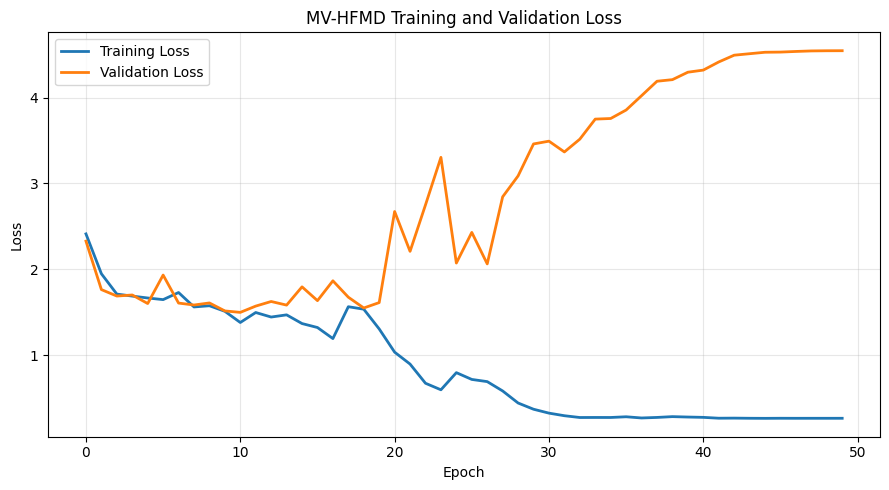

Saved: /kaggle/working/anaecare_mvhfmd_paper_method/plots/01_training_validation_loss.png


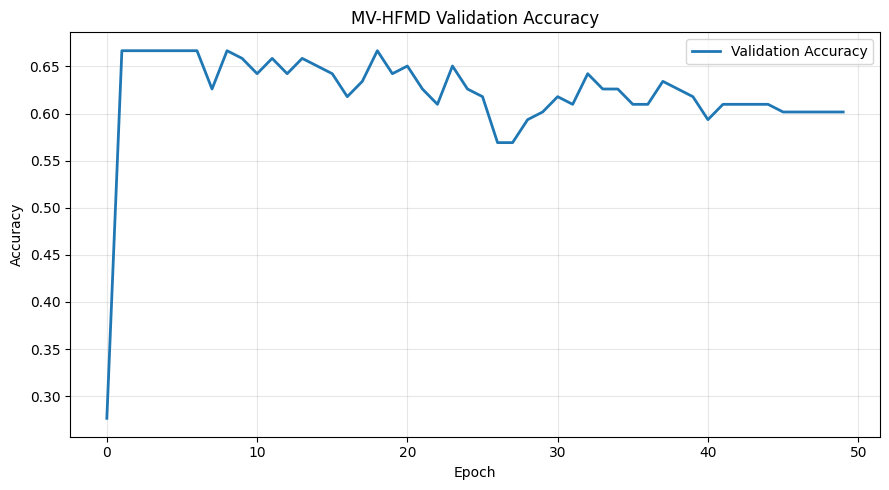

Saved: /kaggle/working/anaecare_mvhfmd_paper_method/plots/02_validation_accuracy.png


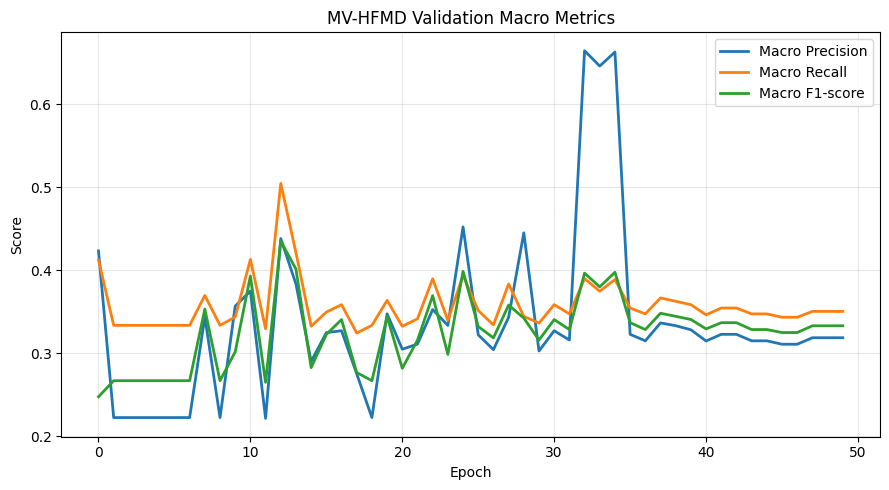

Saved: /kaggle/working/anaecare_mvhfmd_paper_method/plots/03_validation_macro_metrics.png
Saved: /kaggle/working/anaecare_mvhfmd_paper_method/plots/confusion_matrix.csv


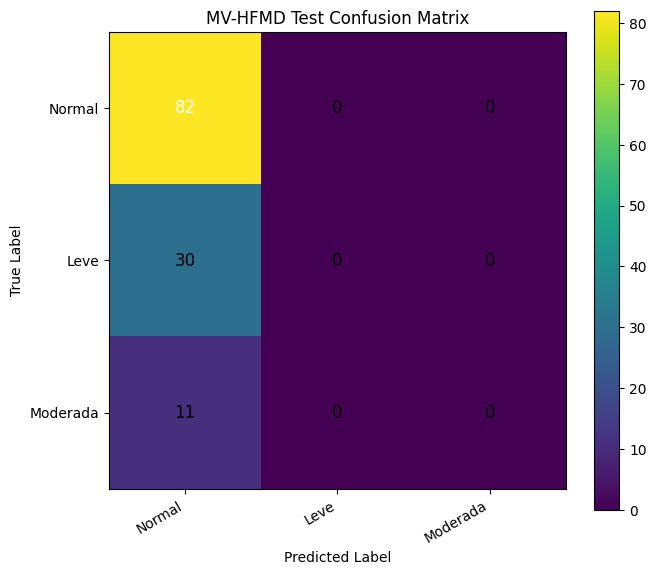

Saved: /kaggle/working/anaecare_mvhfmd_paper_method/plots/04_test_confusion_matrix.png


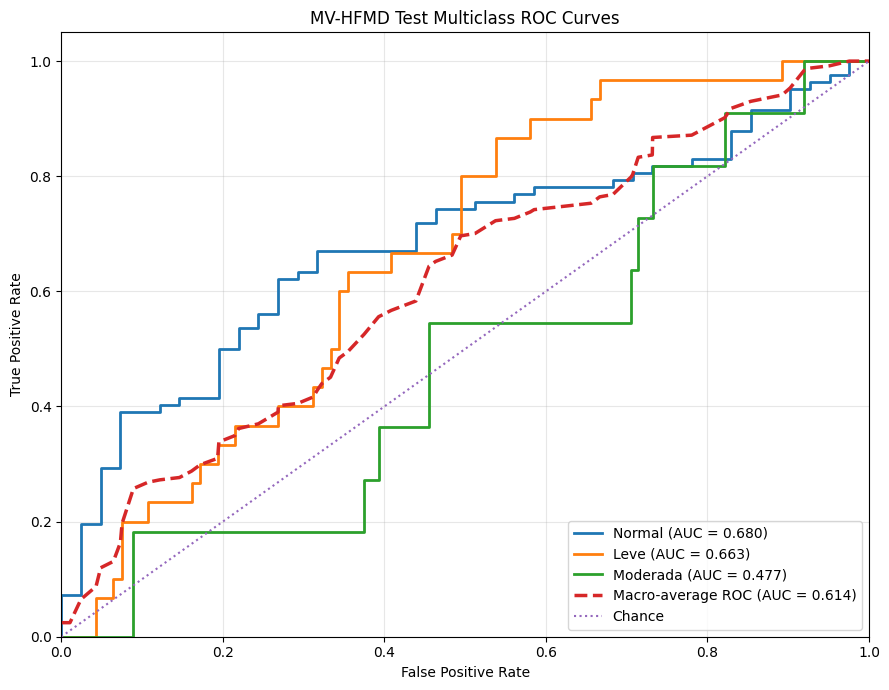

Saved: /kaggle/working/anaecare_mvhfmd_paper_method/plots/05_test_multiclass_ROC.png

Test classification report:

              precision    recall  f1-score   support

      Normal       0.67      1.00      0.80        82
        Leve       0.00      0.00      0.00        30
    Moderada       0.00      0.00      0.00        11

    accuracy                           0.67       123
   macro avg       0.22      0.33      0.27       123
weighted avg       0.44      0.67      0.53       123


PLOTTING COMPLETED
Plot directory: /kaggle/working/anaecare_mvhfmd_paper_method/plots
Updated ZIP: /kaggle/working/AnaeCare_MV_HFMD_Paper_Method_Results.zip
ZIP size (MB): 512.09

Plots currently saved:
 - 01_training_validation_loss.png
 - 02_validation_accuracy.png
 - 03_validation_macro_metrics.png
 - 04_test_confusion_matrix.png
 - 05_test_multiclass_ROC.png
 - confusion_matrix.csv
 - test_classification_report.txt
 - test_per_class_auc.csv


In [14]:

# ============================================================
# AnaeCare MV-HFMD: Post-training plots + update existing ZIP
# No retraining. Existing checkpoints/results are preserved.
# ============================================================

import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    classification_report
)
from sklearn.preprocessing import label_binarize

# ---------- Paths ----------
OUT_DIR = "/kaggle/working/anaecare_mvhfmd_paper_method"
HISTORY_PATH = os.path.join(OUT_DIR, "training_history.csv")
PRED_PATH = os.path.join(OUT_DIR, "test_predictions.csv")
ZIP_PATH = "/kaggle/working/AnaeCare_MV_HFMD_Paper_Method_Results.zip"
PLOT_DIR = os.path.join(OUT_DIR, "plots")

os.makedirs(PLOT_DIR, exist_ok=True)

# ---------- Check saved results ----------
for path in [HISTORY_PATH, PRED_PATH, ZIP_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required saved file not found: {path}\n"
            "Check your existing output directory and ZIP path."
        )

history = pd.read_csv(HISTORY_PATH)
pred = pd.read_csv(PRED_PATH)

print("Training history columns:", history.columns.tolist())
print("Prediction columns:", pred.columns.tolist())
print("History rows:", len(history))
print("Test predictions:", len(pred))

# ---------- Class configuration ----------
CLASS_IDS = [0, 1, 2]
CLASS_NAMES = ["Normal", "Leve", "Moderada"]

# ---------- Helper: find a column ----------
def find_column(df, candidates):
    for col in candidates:
        if col in df.columns:
            return col
    return None

def save_plot(filename):
    path = os.path.join(PLOT_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", path)

# ============================================================
# 1. Training and validation loss
# ============================================================
train_loss_col = find_column(history, ["train_loss"])
val_loss_col = find_column(history, ["val_loss"])

if train_loss_col and val_loss_col:
    plt.figure(figsize=(9, 5))
    plt.plot(history[train_loss_col], label="Training Loss", linewidth=2)
    plt.plot(history[val_loss_col], label="Validation Loss", linewidth=2)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("MV-HFMD Training and Validation Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_plot("01_training_validation_loss.png")
else:
    warnings.warn("Training/validation loss columns not found; loss plot skipped.")

# ============================================================
# 2. Validation accuracy
# ============================================================
acc_col = find_column(history, ["val_accuracy", "val_acc"])

if acc_col:
    plt.figure(figsize=(9, 5))
    plt.plot(history[acc_col], label="Validation Accuracy", linewidth=2)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("MV-HFMD Validation Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_plot("02_validation_accuracy.png")
else:
    warnings.warn("Validation accuracy column not found; accuracy plot skipped.")

# ============================================================
# 3. Validation macro Precision, Recall and F1
# ============================================================
metric_columns = {
    "Macro Precision": find_column(history, ["val_macro_precision"]),
    "Macro Recall": find_column(history, ["val_macro_recall"]),
    "Macro F1-score": find_column(history, ["val_macro_f1"]),
}

available_metrics = {
    label: col for label, col in metric_columns.items() if col is not None
}

if available_metrics:
    plt.figure(figsize=(9, 5))
    for label, col in available_metrics.items():
        plt.plot(history[col], label=label, linewidth=2)
    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.title("MV-HFMD Validation Macro Metrics")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_plot("03_validation_macro_metrics.png")
else:
    warnings.warn("Validation macro metric columns not found; metric plot skipped.")

# ============================================================
# 4. Test confusion matrix heatmap
# ============================================================
required_cols = ["y_true", "y_pred"]
if all(col in pred.columns for col in required_cols):
    y_true = pred["y_true"].astype(int).to_numpy()
    y_pred = pred["y_pred"].astype(int).to_numpy()

    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)

    # Save matrix as CSV as well
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {name}" for name in CLASS_NAMES],
        columns=[f"Predicted {name}" for name in CLASS_NAMES]
    )
    cm_csv_path = os.path.join(PLOT_DIR, "confusion_matrix.csv")
    cm_df.to_csv(cm_csv_path)
    print("Saved:", cm_csv_path)

    plt.figure(figsize=(7, 6))
    plt.imshow(cm, interpolation="nearest")
    plt.title("MV-HFMD Test Confusion Matrix")
    plt.colorbar()
    ticks = np.arange(len(CLASS_NAMES))
    plt.xticks(ticks, CLASS_NAMES, rotation=30, ha="right")
    plt.yticks(ticks, CLASS_NAMES)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    threshold = cm.max() / 2 if cm.size and cm.max() > 0 else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black",
                fontsize=12
            )

    save_plot("04_test_confusion_matrix.png")
else:
    raise KeyError("test_predictions.csv must contain y_true and y_pred columns.")

# ============================================================
# 5. Multiclass one-vs-rest ROC curves
# ============================================================
prob_cols = ["prob_normal", "prob_leve", "prob_moderada"]

if all(col in pred.columns for col in prob_cols):
    y_score = pred[prob_cols].to_numpy(dtype=float)
    y_bin = label_binarize(y_true, classes=CLASS_IDS)

    plt.figure(figsize=(9, 7))
    valid_class_aucs = []
    valid_fprs = []
    valid_tprs = []

    for i, class_name in enumerate(CLASS_NAMES):
        # ROC is undefined if the test set has no positives or no negatives
        if len(np.unique(y_bin[:, i])) < 2:
            warnings.warn(
                f"ROC curve for {class_name} skipped: "
                "test labels contain only one binary outcome."
            )
            continue

        fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
        class_auc = auc(fpr, tpr)

        plt.plot(
            fpr, tpr, linewidth=2,
            label=f"{class_name} (AUC = {class_auc:.3f})"
        )

        valid_class_aucs.append(class_auc)
        valid_fprs.append(fpr)
        valid_tprs.append(tpr)

    # Macro-average ROC curve across classes with valid ROC curves
    if valid_fprs:
        all_fpr = np.unique(np.concatenate(valid_fprs))
        mean_tpr = np.zeros_like(all_fpr)

        for fpr, tpr in zip(valid_fprs, valid_tprs):
            mean_tpr += np.interp(all_fpr, fpr, tpr)

        mean_tpr /= len(valid_fprs)
        macro_curve_auc = auc(all_fpr, mean_tpr)

        plt.plot(
            all_fpr, mean_tpr, linestyle="--", linewidth=2.5,
            label=f"Macro-average ROC (AUC = {macro_curve_auc:.3f})"
        )

        plt.plot([0, 1], [0, 1], linestyle=":", linewidth=1.5,
                 label="Chance")
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("MV-HFMD Test Multiclass ROC Curves")
        plt.legend(loc="lower right")
        plt.grid(True, alpha=0.3)
        save_plot("05_test_multiclass_ROC.png")

        # Save per-class AUC values
        auc_df = pd.DataFrame({
            "Class": CLASS_NAMES[:len(CLASS_IDS)],
            "AUC": [
                auc(roc_curve(y_bin[:, i], y_score[:, i])[0],
                    roc_curve(y_bin[:, i], y_score[:, i])[1])
                if len(np.unique(y_bin[:, i])) == 2 else np.nan
                for i in range(len(CLASS_IDS))
            ]
        })
        auc_df.to_csv(
            os.path.join(PLOT_DIR, "test_per_class_auc.csv"),
            index=False
        )
    else:
        warnings.warn("No valid one-vs-rest ROC curves could be calculated.")
else:
    warnings.warn(
        "Probability columns not found. ROC needs "
        "prob_normal, prob_leve, and prob_moderada."
    )

# ============================================================
# 6. Save a text summary of the test classification report
# ============================================================
report = classification_report(
    y_true, y_pred,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    zero_division=0
)

report_path = os.path.join(PLOT_DIR, "test_classification_report.txt")
with open(report_path, "w", encoding="utf-8") as f:
    f.write("MV-HFMD Test Classification Report\n\n")
    f.write(report)

print("\nTest classification report:\n")
print(report)

# ============================================================
# 7. Add plots to the EXISTING ZIP, preserving prior files
# ============================================================
# Existing checkpoint and result files are not regenerated.
# New files are added under the plots/ directory in the ZIP.
with zipfile.ZipFile(ZIP_PATH, mode="a",
                     compression=zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(PLOT_DIR):
        for filename in files:
            full_path = os.path.join(root, filename)
            arcname = os.path.relpath(full_path, OUT_DIR)
            zf.write(full_path, arcname=arcname)

print("\n" + "=" * 60)
print("PLOTTING COMPLETED")
print("Plot directory:", PLOT_DIR)
print("Updated ZIP:", ZIP_PATH)
print("ZIP size (MB):", round(os.path.getsize(ZIP_PATH) / (1024**2), 2))
print("\nPlots currently saved:")
for filename in sorted(os.listdir(PLOT_DIR)):
    print(" -", filename)
print("=" * 60)


## 10. Reporting notes

- Report this as **MV-HFMD adapted to AnaeCare**, not a reproduction of the Hotels-8k experiment.
- State that the three inputs are YEMAS, PALMAS and UNAS; one representative frame/image is used per view.
- State that the paper's metadata is not part of this model run; only the three visual views are used.
- Preserve `Normal=0`, `Leve=1`, `Moderada=2`.
- Report accuracy, macro precision/recall/F1, macro OVR AUROC and the confusion matrix; inspect minority-class recall, especially `Moderada`.
- Do not compare metrics directly against another notebook unless the patient IDs in train/validation/test are identical.
